Lander Dirix

## Overzicht
* 1. Data en imports
* 2. EDA
    * 2.1 Overzicht van de dataset
    * 2.2 Nummers per artiest en album
    * 2.3 Kolomtypes
    * 2.4 Opschonen van kolommen
        * Onnuttige kolommen
        * Redundante kolommen (duration)
        * Tekstkolommen
        * Verschillende formats (3 precizies van datum, veel placeholder datums, compilaties krijgen de datum van de heruitgave)
    * Sortering en groepering 
        * gesorteerd op releasedatum
        * nummers van hetzelfde album en dezelfde artiest staan bij elkaar
    * Kwaliteit van de data
        * Duplicaten
        * Ontbrekende waarden
        * Outliers
    * splitsen van sets
    *  Doelveld (genre)
        * Aantal genres en verdeling
        * Artiesten per genre
        * Genres per artiest
        * Genres per album
* 3. Splitsen
* 4. Verdiepende EDA
    * Histogrammen per audio feature
    * Outliers
    * Correlatiematrix
    * Boxplots
* 5. Preprocessing en feature engineering
* 6. Modellen en tuning
* 7. Evaluatie
* 8. Conclusie

# 1. Data en imports

## Import statements

In [87]:
import pandas as pd
import seaborn as sn
import numpy as np
import matplotlib.pyplot as plt
import os


original_df = pd.read_csv("./Spotify_tracks_final.csv")

RANDOM_STATE = 1

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)
pd.set_option("display.float_format", "{:.3f}".format)

# 2. EDA

## 2.1 Overzicht van de dataset

In [88]:
n_rows, n_cols = original_df.shape
print(f"Rijen: {n_rows:,}")
print(f"Kolommen: {n_cols}")
print(f"Bestandsgrootte: {os.path.getsize('./Spotify_tracks_final.csv') / 1e9:.2f} GB")
print(f"Geheugengebruik: {original_df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Rijen: 2,112,746
Kolommen: 30
Bestandsgrootte: 0.82 GB
Geheugengebruik: 2.01 GB


In [89]:
original_df.head(10)

,Unnamed: 0,track_name,track_id,album_name,album_id,album_image,album_release_date,album_release_date_precision,artist_name,artist_id,popularity,duration_ms,explicit,preview_url,genre,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,database_shard_id,duration_seconds,duration_minutes
0,0,"Divenire: No. 9, Fly - Intouchables",5u5scm02d5wN6nWFKuqEUK,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,2,265653,False,https://p.scdn.co/mp3-preview/81f71c...,ambient,0.990,0.184,0.033,0.877,1,0.100,-28.184,0,0.037,168.133,3,0.035,0,265.653,4.428
1,1,Spiegel im Spiegel - Heaven,1wV4SNFEXWawsyjBCGwkiw,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,349120,False,https://p.scdn.co/mp3-preview/040ea9...,ambient,0.985,0.250,0.015,0.971,5,0.067,-30.646,1,0.037,136.864,5,0.039,0,349.120,5.819
2,2,Truman Sleeps - The Trumanshow,4gYub3T80gNfU9F4Df98AR,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,1,128039,False,https://p.scdn.co/mp3-preview/e9a7cd...,ambient,0.993,0.269,0.021,0.883,5,0.139,-24.620,0,0.040,69.487,4,0.041,0,128.039,2.134
3,3,The Heart Askes Pleasure First - The...,6sXRgSAQsySTM7kH1pM07Y,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,190960,False,https://p.scdn.co/mp3-preview/9a33da...,ambient,0.995,0.230,0.138,0.885,4,0.101,-19.591,0,0.037,165.197,3,0.171,0,190.960,3.183
4,4,3 Gymnopédies: I. Lent et douloureux,7Eytd0e0mNFiSWIE132H76,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,4,338933,False,https://p.scdn.co/mp3-preview/d31979...,ambient,0.995,0.611,0.002,0.967,7,0.082,-37.782,1,0.286,134.237,3,0.508,0,338.933,5.649
5,5,Comptine d'un autre été - Le fabuleu...,36xrCDskORciDQupSJdoQ0,Discover The Great Classics,6HKSdjtjJGtxmeUrkhSCSf,https://i.scdn.co/image/ab67616d0000...,1950,year,Jeroen van Veen,7o7D77HMHvg1sAmtryKoVy,0,141133,False,https://p.scdn.co/mp3-preview/926917...,ambient,0.968,0.391,0.111,0.933,7,0.099,-21.655,1,0.042,103.047,4,0.079,0,141.133,2.352
6,6,Someone To Watch Over Me,5RcvlmVx2xtFcp2Ta5pw7X,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,54,196666,False,NaN,blues,0.990,0.354,0.085,0.000,7,0.123,-13.738,1,0.035,97.684,1,0.197,1,196.666,3.278
7,7,I've Got A Crush On You,5DIVWgTeJ2fPIxaY9e7ZKn,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,53,196440,False,NaN,blues,0.986,0.455,0.106,0.000,2,0.122,-14.086,1,0.042,66.807,4,0.258,1,196.440,3.274
8,8,But Not For Me,65Dm4aRthohlvuuyKVydIu,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,23,195133,False,NaN,blues,0.986,0.410,0.098,0.000,4,0.174,-14.359,0,0.032,136.431,3,0.240,1,195.133,3.252
9,9,How Long Has This Been Going On?,0HEU3berJ5OBojU8XmEk1c,Ella Sings Gershwin,3DJYxksYYP018jgpOTVXqO,https://i.scdn.co/image/ab67616d0000...,1950-09-11,day,Ella Fitzgerald,5V0MlUE1Bft0mbLlND7FJz,23,197666,False,NaN,blues,0.974,0.303,0.175,0.000,1,0.105,-14.203,0,0.038,168.743,4,0.250,1,197.666,3.294


In [90]:
cols = ["track_id", "album_id", "artist_id", "genre"]
display(original_df[cols].nunique().to_frame("aantal"))

,aantal
track_id,2112746
album_id,464281
artist_id,77854
genre,113


**Conclusie**

De dataset bevat 30 kolommen en meer dan 2,1 miljoen nummers, verdeeld over meer dan 464 duizend albums, bijna 78 duizend artiesten en 113 genres.

Het bestand is 0,82GB groot en neemt 2GB RAM in beslag. Daarom maken we zo weinig mogelijk kopieën en laten we ongebruikte kolommen vroeg vallen.


* **Multiklasse-probleem met vele klassen:** 
Met 113 genres haalt een model dat willekeurig gokt 1/113 = 0,9% accuracy. De echte baseline bepalen we na de analyse van de genreverdeling.
Omdat genres inhoudelijk vaak overlappen, is verwarring te verwachten. Daarom beslissen we later of we alle genres houden, de minst voorkomende genres laten vallen of verwante genres samenvoegen.


* **Groepering in de data:**
De eerste rijen zijn nummers van dezelfde artiest en hetzelfde album met hetzelfde genre. Een willekeurige split zou dus leakage kunnen veroorzaken. Dit onderzoeken we verder bij de verdeling per artiest en album en bepaalt hoe we de data splitsen.


## 2.2 Nummers per artiest en album

In [91]:
per_artiest = original_df.groupby("artist_id").size()
per_album = original_df.groupby("album_id").size()

pd.DataFrame({
    "nummers per artiest": per_artiest.describe(percentiles=[.5, .9, .99]),
    "nummers per album": per_album.describe(percentiles=[.5, .9, .99]),
})


,nummers per artiest,nummers per album
count,77854.000,464281.000
mean,27.137,4.551
std,93.772,5.494
min,1.000,1.000
50%,8.000,2.000
90%,67.000,11.000
99%,256.000,22.000
max,10035.000,315.000


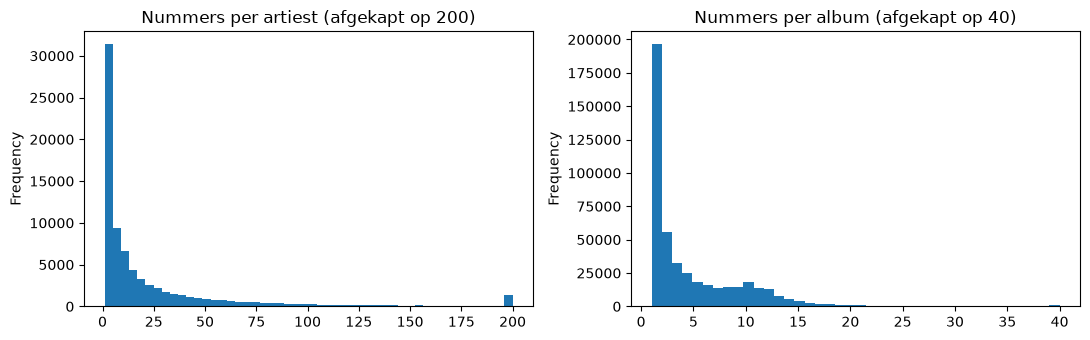

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
per_artiest.clip(upper=200).plot.hist(bins=50, ax=axes[0], title="Nummers per artiest (afgekapt op 200)")
per_album.clip(upper=40).plot.hist(bins=40, ax=axes[1], title="Nummers per album (afgekapt op 40)")
plt.tight_layout(); plt.show()

In [93]:
top_10 = per_artiest.sort_values(ascending=False).head(10)
display(original_df.drop_duplicates("artist_id").set_index("artist_id")
        .loc[top_10.index, ["artist_name"]].assign(n_nummers=top_10))

,artist_name,n_nummers
artist_id,,
5aIqB5nVVvmFsvSdExz408,Johann Sebastian Bach,10035
1U5zgr455OGyIkLNXvDdrf,Traditional,8737
4NJhFmfw43RLBLjQvxDuRS,Wolfgang Amadeus Mozart,6316
1JOQXgYdQV2yfrhewqx96o,Giuseppe Verdi,6104
5as8A4G47Ohu9NSWs3Je8U,Asha Bhosle,5492
61JrslREXq98hurYL2hYoc,Lata Mangeshkar,4214
1C1x4MVkql8AiABuTw6DgE,Richard Wagner,3935
2wOqMjp9TyABvtHdOSOTUS,Ludwig van Beethoven,3558
0roWUeP7Ac4yK4VN6L2gF4,Gioachino Rossini,3487


In [94]:
top1_procent = per_artiest.nlargest(int(len(per_artiest) * 0.01)).sum() / n_rows
print(f"Top 1% van de artiesten bevat {top1_procent:.1%} van alle nummers")
print(f"Grootste artiest: {per_artiest.max() / n_rows:.2%} van alle nummers")

Top 1% van de artiesten bevat 19.4% van alle nummers
Grootste artiest: 0.47% van alle nummers


**Conclusie**

Beide verdelingen zijn sterk rechtsscheef.
De mediaan is 8 nummers per artiest en 2 per album, terwijl het gemiddelde veel hoger ligt (27,1 en 4,6). 
De top 1% van artiesten levert bijna 20% van alle nummers.

De grootste artiesten zijn vooral klassieke componisten (zoals Bach met meer dan 10 duizend nummers).
Dit is waarschijnlijk omdat de artiest vaak de componist is, in plaats van de uitvoerder.
"Traditional" is geen echte artiest maar een verzamelnaam voor onbekende uitvoerders.

* **Groepssplit:** 
Nummers van dezelfde artiest blijven samen in een split. De grootste artiest is ongeveer 0,5% van de data, dus er zouden geen folds mogen zijn die door één artiest is gedomineerd.

* **Verzamelnamen:** 
"Traditional" zal volledig in één split terecht komen. Dat is geen leakage, maar die nummers zijn onderling niet representatief voor één artiest.

* **Nog te controleren:** 
Bestaan zeldzame genres grotendeels uit één artiest, want dan wordt stratificatie moeilijk. Dat bekijken we bij de genreverdeling.

## 2.3 Kolomtypes

In [95]:
print(original_df.dtypes.value_counts())
original_df.dtypes.to_frame("aantal kolommen")

str        11
float64    11
int64       7
bool        1
Name: count, dtype: int64


,aantal kolommen
Unnamed: 0,int64
track_name,str
track_id,str
album_name,str
album_id,str
album_image,str
album_release_date,str
album_release_date_precision,str
artist_name,str
artist_id,str


De dataset bevat 11 tekstkolommen, 11 float-kolommen, 7 int-kolommen en 1 booleaanse kolom. 

Het type zegt niet altijd wat een kolom betekent: kolommen als key, mode en time_signature staan als integer, maar zijn categorisch.

## 2.4 Opschonen van kolommen

In [96]:
# Unnamed: 0 = achtergebleven csv-index?
print("Unnamed: 0 == rij-index:", (original_df["Unnamed: 0"] == original_df.index).all())

print("min:", original_df["Unnamed: 0"].min(), "| max:", original_df["Unnamed: 0"].max(), )

# Duur: drie eenheden voor dezelfde grootheid?
print("seconden == ms / 1000:", np.allclose(original_df["duration_seconds"], original_df["duration_ms"] / 1000))
print("minuten == ms / 60000:", np.allclose(original_df["duration_minutes"], original_df["duration_ms"] / 60000))

Unnamed: 0 == rij-index: False
min: 0 | max: 3924134
seconden == ms / 1000: True
minuten == ms / 60000: True


In [97]:
# database_shard_id: hangt hij samen met jaar of genre?
jaar = original_df["album_release_date"].str[:4].astype(int)
display(original_df.assign(jaar=jaar).groupby("database_shard_id")
        .agg(n=("track_id", "size"), jaar_mediaan=("jaar", "median"),
             n_genres=("genre", "nunique"),
             top_genres=("genre", lambda s: ", ".join(s.value_counts().head(3).index))))

,n,jaar_mediaan,n_genres,top_genres
database_shard_id,,,,
0,30245,2004.000,110,"ambient, indian, classical"
1,44343,1986.000,108,"blues, indian, french"
2,37431,1996.000,109,"british, folk, acoustic"
3,25312,2005.000,110,"children, german, indian"
4,46704,1984.000,106,"classical, blues, french"
...,...,...,...,...
108,9890,2012.000,112,"progressive-house, classical, disco"
109,10115,2014.000,111,"hardstyle, classical, german"
110,5706,2010.000,110,"dubstep, german, indian"


In [98]:
# artist_id versus artist_name
namen_per_id = original_df.groupby("artist_id")["artist_name"].nunique()
ids_per_naam = original_df.groupby("artist_name")["artist_id"].nunique()
print("artist_id's met >1 naam:", (namen_per_id > 1).sum())
print("artist_name's met >1 id:", (ids_per_naam > 1).sum())

artist_id's met >1 naam: 0
artist_name's met >1 id: 420


In [99]:
namen = ids_per_naam[ids_per_naam > 1].index
sub = original_df[original_df["artist_name"].isin(namen)]

# per (naam, id): de top-3 genres als tekst
genres = (sub.groupby(["artist_name", "artist_id"])["genre"]
             .agg(lambda s: ", ".join(s.value_counts().head(3).index)))

# per naam: de genres van twee id's naast elkaar
paren = genres.groupby("artist_name").apply(lambda s: list(s)[:2])
tabel = pd.DataFrame(paren.tolist(), index=paren.index, columns=["genres_id1", "genres_id2"])

tabel.sample(25, random_state=42)

,genres_id1,genres_id2
artist_name,,
Germ,emo,black-metal
Shining,metal,black-metal
John Wayne,brazil,dancehall
The Controllers,punk,soul
Zola,k-pop,french
Camarão,forro,forro
Felix Martin,jazz,show-tunes
Franco,malay,gospel
Anomalie,jazz,black-metal


**artist_id versus artist_name.** Elke `artist_id` hoort bij precies één naam, maar 420 namen komen voor onder meer dan één id (0,5%). Meestal hebben naam-genoten totaal andere genres, wat erop duidt dat het verschillende artiesten zijn die toevallig dezelfde naam hebben. 

Soms is het wel dezelfde artiest met twee profielen (zoals Cafe Jazz Deluxe met jazz of Yosef Moshe Kahana met j-pop). In dit geval is het gevaarlijker voor de split. Dezelfde artiest zou in train en test kunnen zijn. Groeperen op naam vangt dit op en het samen houden van naamgenoten kost niets. Daarom groeperen we op naam in plaats van ID.

**Welke kolommen laten we vallen en welke houden we?**

| Kolom | Beslissing | Reden |
|---|---|---|
| `Unnamed: 0` | Droppen | Achtergebleven index van een groter origineel CSV-bestand: de waarden zijn uniek en stijgend maar lopen op tot 3,9 miljoen, terwijl de dataset maar 2,1 miljoen rijen bevat |
| `track_id`, `album_id`, `artist_id` | Droppen | Identifiers zonder muzikale informatie |
| `album_image`, `preview_url` | Droppen | Urls |
| `database_shard_id` | Droppen | Technische id van de database waarin het record zat. Elke shard bevat rond de 110 van de 113 genres, dus de shard zegt niets over het genre. |
| `duration_ms`, `duration_minutes` | Droppen | Redundant: dezelfde informatie als `duration_seconds` |
| `track_name`, `album_name` | Niet in het hoofdmodel, apart tekstexperiment | Vrije tekst die eerst verwerkt moet worden bevat mogelijk sterke signalen (taal, "Op. 67", "Remix"), maar albumnamen van compilaties noemen vaak letterlijk het genre. Dit kan als uitbreiding onderzocht worden |
| `album_release_date`, `album_release_date_precision` | Droppen na extractie | Gemengde formaten (jaar, jaar-maand, volledige datum). Betrouwbaarheid moet onderzocht worden |
| `artist_name` | Houden, enkel om te groeperen | Wordt geen feature, wel nodig voor de groepssplit |
| `genre` | Houden | Doelveld |
| `duration_seconds` | Houden | Eén kolom voor duration overhouden |
| `release_year` | Houden | Het uitgelezen jaar uit album_release_date |
| `popularity`, `explicit` | Voorlopig houden | Metadata, geen eigenschap van het geluid. Beslissing over gebruik volgt bij de featureselectie |
| `acousticness`, `danceability`, `energy`, `instrumentalness`, `liveness`, `loudness`, `speechiness`, `tempo`, `valence`, `key`, `mode`, `time_signature` | Houden | audiofeatures |

In [100]:
keep = ["artist_name", "genre", "duration_seconds", "popularity", "explicit",
        "acousticness", "danceability", "energy", "instrumentalness", "liveness",
        "loudness", "speechiness", "tempo", "valence", "key", "mode", "time_signature"]

df = original_df[keep].copy()

print(df.shape)
print(f"{df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

df.head()

(2112746, 17)
0.49 GB


,artist_name,genre,duration_seconds,popularity,explicit,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,key,mode,time_signature
0,Jeroen van Veen,ambient,265.653,2,False,0.990,0.184,0.033,0.877,0.100,-28.184,0.037,168.133,0.035,1,0,3
1,Jeroen van Veen,ambient,349.120,0,False,0.985,0.250,0.015,0.971,0.067,-30.646,0.037,136.864,0.039,5,1,5
2,Jeroen van Veen,ambient,128.039,1,False,0.993,0.269,0.021,0.883,0.139,-24.620,0.040,69.487,0.041,5,0,4
3,Jeroen van Veen,ambient,190.960,0,False,0.995,0.230,0.138,0.885,0.101,-19.591,0.037,165.197,0.171,4,0,3
4,Jeroen van Veen,ambient,338.933,4,False,0.995,0.611,0.002,0.967,0.082,-37.782,0.286,134.237,0.508,7,1,3


## 2.5 Sortering en groepering

Volledig gesorteerd op jaar: False


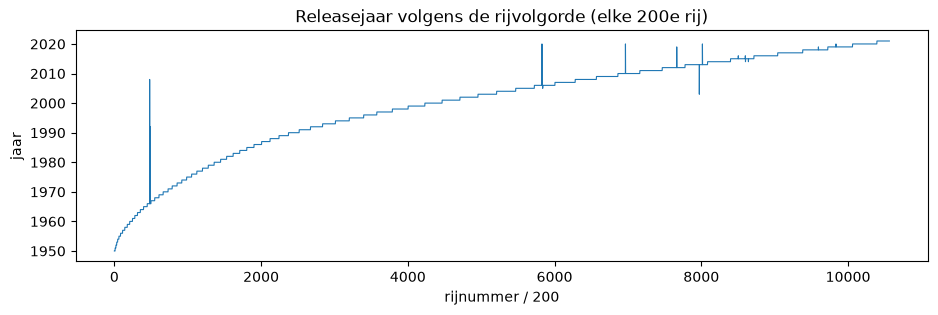

Rijen waar het jaar daalt t.o.v. de vorige rij: 930 van 2,112,746
Aantal aaneengesloten blokken met hetzelfde genre: 6,083


In [101]:
jaar = original_df["album_release_date"].str[:4].astype(int)
print("Volledig gesorteerd op jaar:", jaar.is_monotonic_increasing)

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(jaar.values[::200], lw=.8)
ax.set(title="Releasejaar volgens de rijvolgorde (elke 200e rij)", xlabel="rijnummer / 200", ylabel="jaar")
plt.show()

print(f"Rijen waar het jaar daalt t.o.v. de vorige rij: {(jaar.diff() < 0).sum()} van {n_rows:,}")
print(f"Aantal aaneengesloten blokken met hetzelfde genre: {(original_df['genre'] != original_df['genre'].shift()).sum():,}")


**Conclusie**

De rijen staan (op 930 uitzonderingen na) gesorteerd op releasejaar, en binnen een jaar in ongeveer 6000 blokken van hetzelfde genre (met gemiddeld 350 rijen per blok). Elke combinatie van jaar en genre staat dus in precies één blok.

* **Nooit splitsen op rijvolgorde:** De eerste 80% als trainset nemen is een split op tijd, met oude muziek in train en recente muziek in test. De genreverdeling zou dan ook sterk verschillen tussen train en test. We splitsen dus nooit op positie.

* **Groepering op artiest:** Nummers van dezelfde artiest en hetzelfde album staan naast elkaar. Een willekeurige split zou ze over train en test verdelen. We groeperen daarom op artiest.

## 2.6 Kwaliteit van de data

### Duplicaten

In [102]:
# Rijen waarvan track_id meer dan 1x voorkomt
dup_track = original_df["track_id"].duplicated(keep=False)
print("Rijen waarvan track_id meer dan 1x voorkomt:", dup_track.sum(),
      f"({dup_track.mean():.1%})")

Rijen waarvan track_id meer dan 1x voorkomt: 0 (0.0%)


In [103]:
# Nummers met dezelfde titel en artiest
dup = original_df.duplicated(subset=["artist_name", "track_name"], keep=False)
print(f"Nummers met zelfde titel en artiest: {dup.sum():,} ({dup.mean():.1%})")

Nummers met zelfde titel en artiest: 0 (0.0%)


In [104]:
# Dezelfde opname onder een andere titel of artiest met identieke audiofeatures en duratie
audio = ["acousticness", "danceability", "energy", "instrumentalness", "liveness", "loudness",
         "speechiness", "tempo", "valence", "key", "mode", "time_signature", "duration_ms"]

dup_audio = original_df.duplicated(subset=audio, keep=False)
print(f"Rijen met identieke audiofeatures: {dup_audio.sum()} ({dup_audio.mean():.1%})")

genres_per_groep = original_df[dup_audio].groupby(audio)["genre"].nunique()
print(f"Groepen met duplicaten: {len(genres_per_groep)}, waarvan met tegenstrijdig genre: {(genres_per_groep > 1).sum()}")

col = audio + ["track_name", "artist_name", "genre"]
eerste = original_df.loc[dup_audio, col].drop_duplicates(audio)
tweede = original_df.loc[original_df.duplicated(audio), col].drop_duplicates(audio)
display(eerste.merge(tweede, on=audio, suffixes=("_1", "_2")).drop(columns=audio).head(10))

Rijen met identieke audiofeatures: 28200 (1.3%)
Groepen met duplicaten: 13134, waarvan met tegenstrijdig genre: 1827


,track_name_1,artist_name_1,genre_1,track_name_2,artist_name_2,genre_2
0,"Die Zauberflöte, K. 620: Ein Mädchen...",Wolfgang Amadeus Mozart,classical,"Die Zauberflöte, K. 620, Act II: ""Ei...",Wolfgang Amadeus Mozart,classical
1,"Warnung, K. 433/416C: Männer suchen ...",Wolfgang Amadeus Mozart,classical,"Warnung, K. 433/416C: Männer suchen ...",Staatskapelle Dresden,classical
2,"Le nozze di Figaro, K. 492: Overture",Wolfgang Amadeus Mozart,classical,"Die Entführung aus dem Serail, K. 38...",Staatskapelle Dresden,classical
3,Dharti Hamari Pe Tu Nit Nit,Surinder Kaur,folk,Dil Hai Lagane Ke Liye,Shamshad Begum,pop
4,Konialis,Stathis Koukoularis,folk,Konialis Dosekanisiakos,Stathis Koukoularis,folk
5,Eho Meinei o Ftohos,Stelios Kazantzidis,pop,Den zontaneuoun oi nekroi,Stelios Kazantzidis,pop
6,Give Mother My Crown,Lester Flatt,bluegrass,Give Mother My Crown (with The Foggy...,Flatt & Scruggs,bluegrass
7,Rhapsody for Cello and Piano No. 1,Béla Bartók,classical,Rhapsody for Cello and Piano No. 1: ...,Béla Bartók,classical
8,"Symphony No. 3 in F Major, Op. 90: I...",Johannes Brahms,classical,III. Poco allegretto,Johannes Brahms,german
9,"Ae Mere Dil Kahin Aur Chal, Pt. 2",Lata Mangeshkar,pop,"Ae Mere Dil Kahin Aur Chal, Pt. 1",Lata Mangeshkar,pop


**Conclusie**

`track_id` is uniek en er bestaat geen enkel paar met dezelfde titel en artiest. 

Toch hebben 1,3% van de rijen exact dezelfde audiofeatures als een andere rij. Het gaat om dezelfde opname onder een licht andere titel of artiestnaam. In 1827 groepen heeft dezelfde opname zelfs verschillende genres.

* **Leakage:** Als de kopieën bij een andere artiestnaam horen, kunnen ze in train en test terechtkomen. Het model wordt dan getest op een nummer dat het al gezien heeft.
* **Labelruis:** Exact dezefde input met een ander genre kan nooit juist voorspelt worden.

**Beslissing:** we houden per groep met dezelfde features enkel de eerste rij. De data is op jaar gesorteerd, dus het eerste record is waarschijnlijk het origineel.

In [105]:
first_copy = ~original_df.duplicated(subset=audio)
n_voor = len(df)
df = df[first_copy]
print(f"Duplicaten: {n_voor} -> {len(df)} rijen ({n_voor - len(df)} verwijderd)")


Duplicaten: 2112746 -> 2097680 rijen (15066 verwijderd)


### Ontbrekende waarden

In [106]:
# Kolommen met ontbrekende waarden
na = original_df.isna().sum()
display(na[na > 0].to_frame("ontbrekend").assign(procent=lambda t: t["ontbrekend"] / n_rows * 100))
print(f"popularity == 0: {(original_df['popularity'] == 0).mean():.1%}")

,ontbrekend,procent
track_name,6,0.000
album_name,6,0.000
album_image,491,0.023
artist_name,17,0.001
preview_url,325237,15.394


popularity == 0: 20.2%


**Conclusie**

Er ontbreken enkel waarden in tekstkolommen. `preview_url` en `album_image` laten we toch al vallen. 
De 17 rijen zonder `artist_name` kunnen we niet groeperen bij het splitsen, dus worden ze verwijdert.

20% van de nummers heeft `popularity` 0. Dat is geen ontbrekende waarde maar een nummer dat bijna niet beluisterd wordt.

In [107]:
n_voor = len(df)
df = df[df["artist_name"].notna()]
print(f"Zonder artiest: {n_voor} -> {len(df)} rijen ({n_voor - len(df)} verwijderd)")

Zonder artiest: 2097680 -> 2097663 rijen (17 verwijderd)


### Onmogelijke waarden en outliers

In [108]:
checks = {
    "tempo == 0": original_df["tempo"] == 0,
    "time_signature == 0": original_df["time_signature"] == 0,
    "duration < 10 sec": original_df["duration_seconds"] < 10,
    "duration < 30 sec": original_df["duration_seconds"] < 30,
    "duration > 20 min": original_df["duration_seconds"] > 20 * 60,
}
display(pd.DataFrame({
    "aantal": {k: v.sum() for k, v in checks.items()},
    "procent": {k: v.mean() * 100 for k, v in checks.items()},
    "top-3 genres": {k: ", ".join(original_df.loc[v, "genre"].value_counts().head(3).index) for k, v in checks.items()},
}))

,aantal,procent,top-3 genres
tempo == 0,2,0.000,sleep
time_signature == 0,64,0.003,"opera, classical, sleep"
duration < 10 sec,1,0.000,indian
duration < 30 sec,3640,0.172,"grindcore, german, comedy"
duration > 20 min,5071,0.240,"indian, ambient, sleep"


**Conclusie**

Een tempo van 0 BPM of een time_signature van 0 (64 rijen) zijn onmogelijk. Deze rijen verwijderen we.

Heel lange nummers zijn mogelijk (zoals een opera-akte of een uur regengeluid). Deze waarden zijn juist informatief voor het genre en houden we.

In [109]:
n_voor = len(df)
df = df[(df["tempo"] > 0) & (df["time_signature"] > 0)]
print(f"Onmogelijke waarden: {n_voor} -> {len(df)} rijen ({n_voor - len(df)} verwijderd)")

Onmogelijke waarden: 2097663 -> 2097600 rijen (63 verwijderd)


### Releasedatums

album_release_date_precision
day      1739350
year      369943
month       3453
Name: count, dtype: int64

'day'-datums die op 1 januari vallen: 18.8%
Jaren: 1950 - 2021


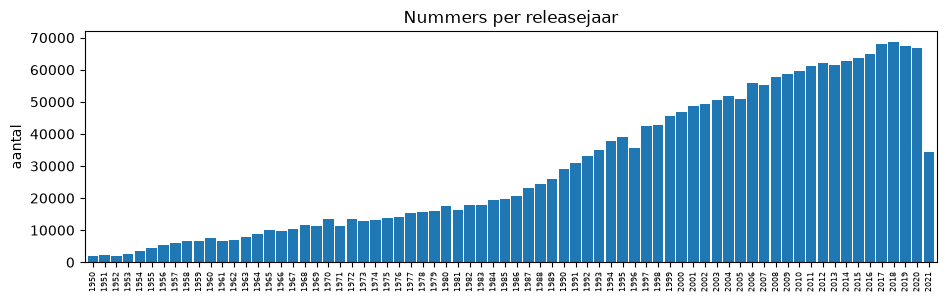

In [110]:
precisie = original_df["album_release_date_precision"]
print(precisie.value_counts())

jaar = original_df["album_release_date"].str[:4].astype(int)

print(f"\n'day'-datums die op 1 januari vallen: {original_df.loc[precisie == "day", 'album_release_date'].str.endswith('-01-01').mean():.1%}")
print(f"Jaren: {jaar.min()} - {jaar.max()}")

fig, ax = plt.subplots(figsize=(11, 3))
jaar.value_counts().sort_index().plot.bar(ax=ax, width=.9)
ax.set(title="Nummers per releasejaar", xlabel="", ylabel="aantal")
ax.tick_params(axis="x", labelsize=6)
plt.show()

**Conclusie**

De datum heeft drie formaten (jaar, jaar-maand en volledige datum). Van de volledige datums valt 18,8% op 1 januari. De echte datum is waarschijnlijk niet gekend. Enkel het jaar is dus betrouwbaar, en daarom houden we alleen `release_year`.

Ook het jaar is ruis: het is de datum van het album. Een compilatie of heruitgave krijgt het jaar van de heruitgave. `release_year` zegt dus iets over wanneer het album uitkwam, niet altijd over het tijdperk van de muziek. 

De eerste nummers in de dataset zijn van 1950, dit kan erop wijzen dat de dataset vooraf gefilterd werd.

In [71]:
df["release_year"] = original_df["album_release_date"].str[:4].astype(int)

## 2.7 Doelveld

### Aantal genres en verdeling

In [117]:
genre_counts = df["genre"].value_counts()
genre_counts.describe()

count     113.000
mean    18562.832
std     10537.146
min        66.000
25%     10128.000
50%     17569.000
75%     25213.000
max     47973.000
Name: count, dtype: float64

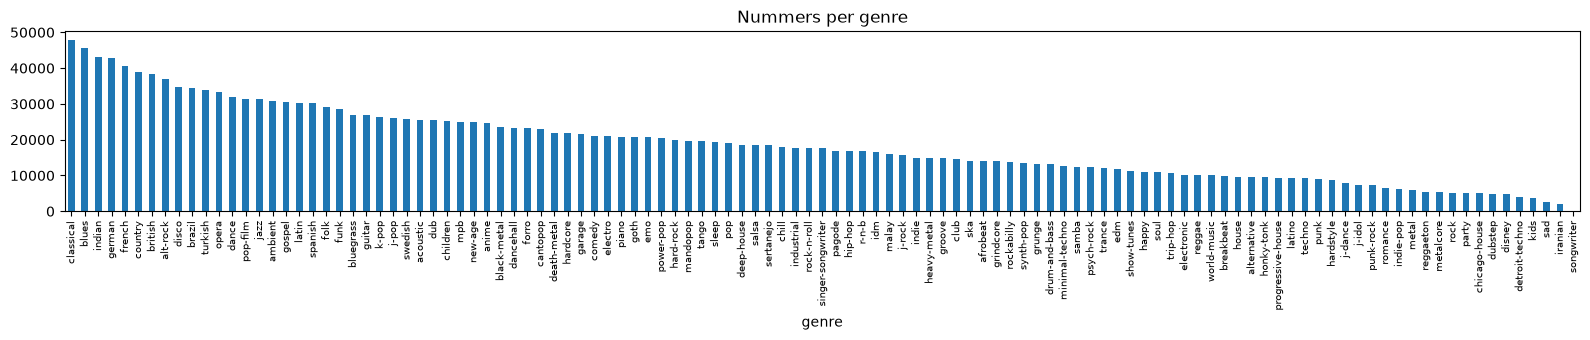

In [124]:
fig, ax = plt.subplots(figsize=(16, 3.5))
genre_counts.plot.bar(ax=ax, title="Nummers per genre")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

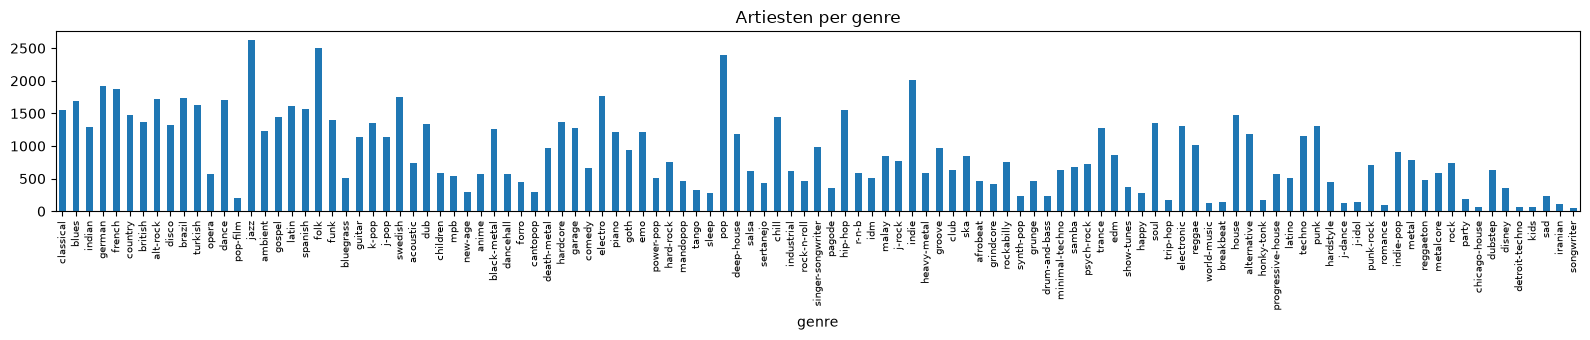

In [127]:
artiesten_per_genre = df.groupby("genre")["artist_name"].nunique()

fig, ax = plt.subplots(figsize=(16, 3.5))
artiesten_per_genre[genre_counts.index].plot.bar(ax=ax, title="Artiesten per genre")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

**Conclusie**

De 113 genres zijn redelijk gebalanceerd: de meeste hebben tussen 10 en 45 duizend nummers. Enkel songwriter is een uitschieter met minder dan 100 nummers. 

Het aantal artiesten per genre verschilt veel meer: sommige genres steunen op minder dan 100 artiesten. Een model ziet daar dus weinig verschillende "stemmen" en riskeert de stijl van die paar artiesten te leren in plaats van het genre.

Belangrijker is wat de genres zijn. Ze zijn niet allemaal muzikale stijlen:

* **Taal of regio:** indian, german, french, british, ...
* **Stemming of gelegenheid:** happy, sad, romance, ...
* **Doelpubliek of medium:** children, disney, anime, show-tunes, ...
* **Instrument of vaag:** guitar, garage, world-music, ...

Deze labels zijn vaak niet te voorspellen uit audiofeatures, of ze overlappen volledig met andere genres.

### Genres per artiest en album

In [128]:
genres_per_artiest = df.groupby("artist_name")["genre"].nunique()
print(f"Artiesten met >1 genre: {(genres_per_artiest > 1).mean():.1%}")

telling = df.groupby(["artist_name", "genre"]).size()
print(f"Nummers in het meest voorkomende genre van hun artiest: {telling.groupby(level=0).max().sum() / len(df):.1%}")

genres_per_album = original_df.loc[df.index].groupby("album_id")["genre"].nunique()
print(f"Albums met >1 genre: {(genres_per_album > 1).mean():.1%}")

Artiesten met >1 genre: 20.4%
Nummers in het meest voorkomende genre van hun artiest: 88.6%
Albums met >1 genre: 11.8%


**Conclusie**

80% van de artiesten heeft maar één genre, en bijna 90% van de nummers heeft het meest voorkomende genre van hun artiest. Het genre is dus grotendeels een eigenschap van de artiest, niet van het nummer.

* **Gevolg voor de split:** Dit bevestigt de keuze om te groeperen op artiest. Anders kan een model de artiest herkennen in plaats van het genre, en is de testscore te optimistisch.

* **Labelruis:** 12% van de albums heeft nummers met verschillende genres, terwijl ze meestal hetzelfde klinken. Het genre volgt dus niet altijd uit de muziek, wat de  haalbare accuracy beperkt.